# TF02 — NumPyで作る1ブロックのVision Transformer：Fashion-MNIST

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ilu-h-bando/dl-tutorial/blob/main/vision/TF02_vision_transformer_fashion.ipynb)

`TF01_tiny_gpt_waka.ipynb` の **64次元・4ヘッド・SwiGLU・手書きの逆伝播・AdamW** を再利用し、
和歌の次文字予測を、服・靴・バッグなど **10種類の画像分類** に置き換えます。
PyTorch / TensorFlowや学習済みモデルは使いません。必要な外部ライブラリは **NumPyとMatplotlibだけ** です。

## このノートで体験すること
- Fashion-MNISTを公式リポジトリから自動取得し、実際の画像と正解を見る。
- 28×28画像を設定したサイズのパッチに分け、各パッチを64次元のベクトルにする（初期設定7×7、16パッチ）。
- 画像をまとめるCLSトークンを追加し、パッチ数＋1トークン（初期設定17）を1ブロックのTransformerへ渡す。
- 学習前後の正解率・予測画像・混同行列を比較する。
- 4ヘッドのAttentionと、パラメータの実際の個数を確認する。

| TF01の和歌GPT | TF02の小さなViT |
|---|---|
| 文字ID → Embedding表 | 画素 → パッチ → 学習するLinear |
| 文字の位置情報 | CLSと各パッチそれぞれの学習する位置Embedding |
| 未来を見せない因果マスク | マスクなし。画像全体を参照 |
| 全位置で次の文字を予測 | CLSの最終表現から画像の10クラスを予測 |
| 自己回帰で文字を生成 | 画像1枚につき1回の順伝播で分類 |

原型ViTのMLPはGELUですが、この教材はTF01との対応が追えるよう **SwiGLUを維持したViTの変種** です。

最新の比較結果は末尾の「全パッチを8エポック目で揃えた比較」です。通常の評価モデルと最終更新時点のモデルの違いも、末尾で説明しています。


## 動かし方と時間の目安

- **Google Colab**：上の「Open in Colab」ボタン →「ランタイム > すべてのセルを実行」
- **手元のJupyter**：上から順にセルを実行

ボタンの参照先はGitHubの `ilu-h-bando/dl-tutorial` の `main/vision/TF02_vision_transformer_fashion.ipynb` です。
GitHub上の公開版をボタンから開けます。ローカルのファイルをColabへアップロードして実行することもできます。
初回だけインターネット接続が必要です。データは作業フォルダの `fashion_mnist/` に保存し、次回から再利用します。

初期設定は公式訓練60,000枚を学習54,000枚・検証6,000枚に分け、8エポック学習します。
**学習ループは300秒または8エポックの早い方で終了**します。
各エポックでは54,000枚をシャッフルし、すべて1回ずつ使います（最後の小さいバッチも使用）。
300秒はステップ間で判定するため、最後の1ステップ・検証処理ぶんは超過する場合があります。
ダウンロード・勾配チェック・最終評価・図の描画時間は別です。精度や所要時間はCPU環境で変わります。
NumPy実装なので、ColabでGPUを選択してもGPU計算にはなりません。

**パッチサイズは設定セルの `PATCH = 7` を `1`・`2`・`4`・`7`・`14`・`28` に変更します。**
設定を変えたら設定セルから順に再実行してください。学習セルは再実行すると初期化から学習し直します。
パッチ1・2では処理量が増え、300秒以内に8エポックを完了できない場合があります。
300秒制限は学習ループのみで、学習前・学習後の検証や最終テストの所要時間は含みません。


In [1]:
# 小さい行列ではBLASのスレッドを増やすと、かえって遅くなることがあります。
# NumPyの読み込み前に設定します（既に読み込んだ場合はカーネル再起動が確実です）。
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import matplotlib.pyplot as plt
import time, gzip, hashlib, struct, urllib.request, json
from pathlib import Path

# 利用可能な場合だけ、既にロード済みのBLASにもスレッド制限を適用します。
try:
    from threadpoolctl import threadpool_limits
    _blas_limit = threadpool_limits(limits=1, user_api='blas')
except ImportError:
    _blas_limit = None

SEED = 0
IMAGE_SIZE = 28
PATCH = 7  # 1, 2, 4, 7, 14, 28 から選択。変更後はこのセルからすべて再実行
SUPPORTED_PATCHES = (1, 2, 4, 7, 14, 28)
if isinstance(PATCH, (bool, np.bool_)) or not isinstance(PATCH, (int, np.integer)) or PATCH not in SUPPORTED_PATCHES:
    raise ValueError(f'PATCHは{SUPPORTED_PATCHES}のいずれかを指定してください: {PATCH!r}')
GRID = IMAGE_SIZE // PATCH
N_PATCH = GRID * GRID
PATCH_DIM = PATCH * PATCH
D = 64
N_HEAD = 4
HD = D // N_HEAD
D_FF = 256
N_CLASS = 10
N_TOKEN = N_PATCH + 1  # CLS + パッチ

TRAIN_PER_CLASS = 5400  # クラスごとに6000 - 検証600
VAL_PER_CLASS = 600
EPOCHS = 8
REQUESTED_BATCH = 32
REQUESTED_EVAL_BATCH = 128
# Attention配列1枚ぶんの要素数を目安にバッチを抑える。総メモリの上限ではありません。
MAX_ATTENTION_ELEMENTS = 2_500_000
if REQUESTED_BATCH < 1 or REQUESTED_EVAL_BATCH < 1 or MAX_ATTENTION_ELEMENTS < 1:
    raise ValueError('バッチとAttention予算は1以上にしてください')
SAFE_BATCH = max(1, MAX_ATTENTION_ELEMENTS // (N_HEAD * N_TOKEN * N_TOKEN))
BATCH = min(REQUESTED_BATCH, SAFE_BATCH)
EVAL_BATCH = min(REQUESTED_EVAL_BATCH, SAFE_BATCH)
STEPS = None  # 分割後、ceil(学習枚数 / BATCH) * EPOCHSから計算
MAX_TRAIN_SECONDS = 300.0  # Noneならステップ数だけで終了
EVAL_EVERY = None  # 各エポック末に検証する
LR = 2e-3
WEIGHT_DECAY = 0.01
DROPOUT = 0.05
USE_POSITION = True
DATA_DIR = Path('fashion_mnist')
OUTPUT_DIR = Path('tf02_results') / f'patch_{PATCH}'  # パッチサイズ別に保存

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
CLASS_NAMES_JA = ['Tシャツ', 'ズボン', 'プルオーバー', 'ドレス', 'コート',
                  'サンダル', 'シャツ', 'スニーカー', 'バッグ', 'アンクルブーツ']
assert IMAGE_SIZE % PATCH == 0 and D % N_HEAD == 0
assert 0 <= DROPOUT < 1 and EPOCHS >= 1 and BATCH >= 1
assert TRAIN_PER_CLASS > 0 and VAL_PER_CLASS > 0
assert MAX_TRAIN_SECONDS is None or MAX_TRAIN_SECONDS > 0
print(f'NumPy {np.__version__}: {N_PATCH} patches + CLS = {N_TOKEN} tokens')
print(f'PATCH={PATCH}: grid={GRID}x{GRID}, pixels/patch={PATCH_DIM}')
print(f'D={D}, heads={N_HEAD}, head_dim={HD}, MLP={D_FF}, blocks=1')
print(f'Batch: train={BATCH} (requested {REQUESTED_BATCH}), eval={EVAL_BATCH} (requested {REQUESTED_EVAL_BATCH})')
print('Results:', OUTPUT_DIR)
print(' patch | patches | tokens | attention elements/head | vs PATCH=7')
for patch_size in SUPPORTED_PATCHES:
    count = (IMAGE_SIZE // patch_size) ** 2
    tokens = count + 1
    print(f'{patch_size:6d} | {count:7d} | {tokens:6d} | {tokens*tokens:23,d} | {(tokens/17)**2:10.2f}x')


NumPy 2.2.6: 16 patches + CLS = 17 tokens
PATCH=7: grid=4x4, pixels/patch=49
D=64, heads=4, head_dim=16, MLP=256, blocks=1
Batch: train=32 (requested 32), eval=128 (requested 128)
Results: tf02_results\patch_7
 patch | patches | tokens | attention elements/head | vs PATCH=7
     1 |     784 |    785 |                 616,225 |    2132.27x
     2 |     196 |    197 |                  38,809 |     134.29x
     4 |      49 |     50 |                   2,500 |       8.65x
     7 |      16 |     17 |                     289 |       1.00x
    14 |       4 |      5 |                      25 |       0.09x
    28 |       1 |      2 |                       4 |       0.01x


## 1. Fashion-MNISTをダウンロードする

Zalando Researchの公開データです。28×28の白黒画像で、公式訓練60,000枚・公式テスト10,000枚があります。
4つのgzipファイルを公式GitHubから取得し、**公式READMEのMD5とIDX形式・件数を確認**します。
MD5は配布ファイルとの一致を確認するために使います。失敗時は不完全なファイルをキャッシュしません。

| ID | 種類 | ID | 種類 |
|---|---|---|---|
| 0 | Tシャツ | 5 | サンダル |
| 1 | ズボン | 6 | シャツ |
| 2 | プルオーバー | 7 | スニーカー |
| 3 | ドレス | 8 | バッグ |
| 4 | コート | 9 | アンクルブーツ |

出典：[Fashion-MNIST公式](https://github.com/zalandoresearch/fashion-mnist)


In [2]:
FILES = {
    'train-images-idx3-ubyte.gz': ('8d4fb7e6c68d591d4c3dfef9ec88bf0d', 60000, 'images'),
    'train-labels-idx1-ubyte.gz': ('25c81989df183df01b3e8a0aad5dffbe', 60000, 'labels'),
    't10k-images-idx3-ubyte.gz': ('bef4ecab320f06d8554ea6380940ec79', 10000, 'images'),
    't10k-labels-idx1-ubyte.gz': ('bb300cfdad3c16e7a12a480ee83cd310', 10000, 'labels'),
}
BASE_URL = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'

def md5_file(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def download_checked(name):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    path = DATA_DIR / name
    expected = FILES[name][0]
    if path.is_file() and md5_file(path) == expected:
        print('cache OK:', name)
        return path
    temp = path.with_suffix(path.suffix + '.part')
    for attempt in range(3):
        try:
            print('download:', name, f'(attempt {attempt + 1})', flush=True)
            request = urllib.request.Request(BASE_URL + name, headers={'User-Agent': 'TF02-Fashion-MNIST/1.0'})
            with urllib.request.urlopen(request, timeout=90) as response, open(temp, 'wb') as out:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    out.write(chunk)
            if md5_file(temp) != expected:
                raise ValueError('配布元のMD5と一致しません: ' + name)
            temp.replace(path)
            return path
        except Exception as error:
            temp.unlink(missing_ok=True)
            if attempt == 2:
                raise RuntimeError('データ取得に失敗しました。通信を確認してこのセルを再実行してください: ' + name) from error
            time.sleep(attempt + 1)

def read_idx(name):
    path = download_checked(name)
    _, count, kind = FILES[name]
    with gzip.open(path, 'rb') as f:
        raw = f.read()
    if kind == 'images':
        magic, n, rows, cols = struct.unpack('>IIII', raw[:16])
        assert (magic, n, rows, cols) == (2051, count, IMAGE_SIZE, IMAGE_SIZE)
        assert len(raw) == 16 + count * IMAGE_SIZE * IMAGE_SIZE
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, rows, cols).copy()
    magic, n = struct.unpack('>II', raw[:8])
    assert (magic, n) == (2049, count) and len(raw) == 8 + count
    labels = np.frombuffer(raw, dtype=np.uint8, offset=8).astype(np.int64)
    assert labels.min() == 0 and labels.max() == 9
    return labels

raw_train = read_idx('train-images-idx3-ubyte.gz')
raw_train_y = read_idx('train-labels-idx1-ubyte.gz')
raw_test = read_idx('t10k-images-idx3-ubyte.gz')
raw_test_y = read_idx('t10k-labels-idx1-ubyte.gz')
print('official train:', raw_train.shape, '/ official test:', raw_test.shape)


cache OK: train-images-idx3-ubyte.gz
cache OK: train-labels-idx1-ubyte.gz
cache OK: t10k-images-idx3-ubyte.gz
cache OK: t10k-labels-idx1-ubyte.gz
official train: (60000, 28, 28) / official test: (10000, 28, 28)


## 2. 訓練・検証・テストを分けて画像を見る

公式訓練60,000枚を、クラスごとに学習5,400枚・検証600枚に分けます。
検証IDを先に固定し、残りを学習用に使うため、60,000枚すべてがどちらかに入ります。
同じSEED・VAL_PER_CLASSなら、学習枚数を減らしても検証IDは変わりません。
**検証と訓練で画像IDは重なりません。公式テスト10,000枚は最後の評価まで学習に使いません。**
画素値を `0〜255 → -1〜1` に変換します。これは学習するパラメータを持たない固定の前処理です。
グラフのラベルは日本語フォントの追加インストールを避けるため英語にしています。


train: 54000 validation: 6000 test (reserved): 10000
epochs=8, steps/epoch=1688, maximum steps=13504
train class counts: [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400]
val   class counts: [600 600 600 600 600 600 600 600 600 600]


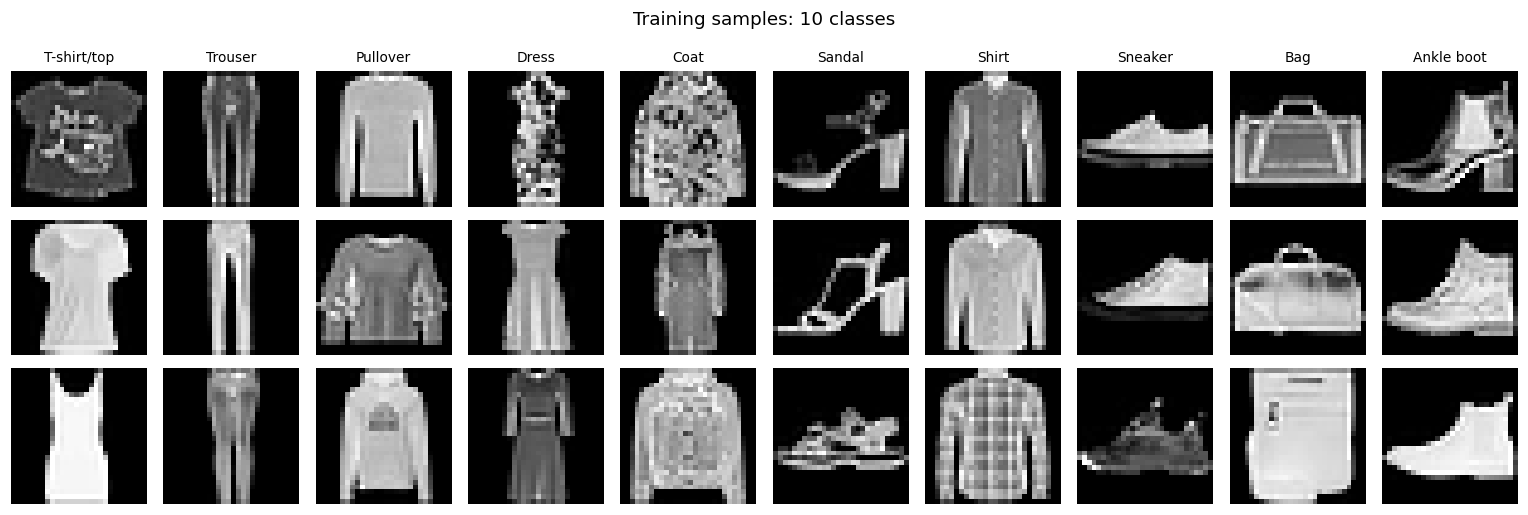

In [3]:
def split_balanced(labels, train_per_class, val_per_class, seed):
    r = np.random.default_rng(seed)
    train_ids, val_ids = [], []
    for c in range(N_CLASS):
        ids = r.permutation(np.flatnonzero(labels == c))
        assert len(ids) >= train_per_class + val_per_class, f'class {c}: 選択枚数が多すぎます'
        val_ids.extend(ids[:val_per_class])
        train_ids.extend(ids[val_per_class:val_per_class + train_per_class])
    train_ids = r.permutation(np.array(train_ids))
    val_ids = r.permutation(np.array(val_ids))
    assert not np.intersect1d(train_ids, val_ids).size
    return train_ids, val_ids

def normalize(images):
    return images.astype(np.float32) / np.float32(127.5) - np.float32(1.0)

train_ids, val_ids = split_balanced(raw_train_y, TRAIN_PER_CLASS, VAL_PER_CLASS, SEED)
assert len(train_ids) + len(val_ids) == len(raw_train_y), '公式訓練60,000枚をすべて分割してください'
assert np.array_equal(np.sort(np.concatenate([train_ids, val_ids])), np.arange(len(raw_train_y)))
STEPS_PER_EPOCH = (len(train_ids) + BATCH - 1) // BATCH
STEPS = EPOCHS * STEPS_PER_EPOCH
EVAL_EVERY = STEPS_PER_EPOCH
X_train, y_train = normalize(raw_train[train_ids]), raw_train_y[train_ids]
X_val, y_val = normalize(raw_train[val_ids]), raw_train_y[val_ids]
print('train:', len(y_train), 'validation:', len(y_val), 'test (reserved):', len(raw_test_y))
print(f'epochs={EPOCHS}, steps/epoch={STEPS_PER_EPOCH}, maximum steps={STEPS}')
print('train class counts:', np.bincount(y_train, minlength=N_CLASS))
print('val   class counts:', np.bincount(y_val, minlength=N_CLASS))

fig, axes = plt.subplots(3, N_CLASS, figsize=(14, 4.8))
for c in range(N_CLASS):
    indices = np.flatnonzero(y_train == c)[:3]
    for row, idx in enumerate(indices):
        axes[row, c].imshow(X_train[idx], cmap='gray', vmin=-1, vmax=1)
        axes[row, c].axis('off')
        if row == 0:
            axes[row, c].set_title(CLASS_NAMES[c], fontsize=9)
fig.suptitle('Training samples: 10 classes')
plt.tight_layout(); plt.show()


## 3. 画像をパッチに分割する：文字EmbeddingからPatch Embeddingへ

パッチの一辺を `PATCH` とすると、`GRID = 28 // PATCH`、パッチ数は `GRID ** 2`、
1パッチの画素数は `PATCH ** 2` です。初期設定7では4×4＝16パッチ、各49画素です。
各パッチを1列に並べ、`patch @ Wpatch + bpatch` で64次元に変換します。
パッチサイズを変えるとパッチ変換と位置Embeddingの形・パラメータ数も変わるため、モデルを初期化して学習し直します。
**画像Encoderを別に追加するのではなく、この変換と後ろのTransformer全体が小さなViTです。**

このあと画像を代表する **CLSトークン** を先頭に追加します。
CLSの初期ベクトルは全画像で共通の学習パラメータで、Attentionを通して画像の情報を受け取ります。
位置EmbeddingもCLSと各パッチ位置に1本ずつあり、画像間で共有します。


images: (54000, 28, 28) -> patches: (54000, 16, 49)


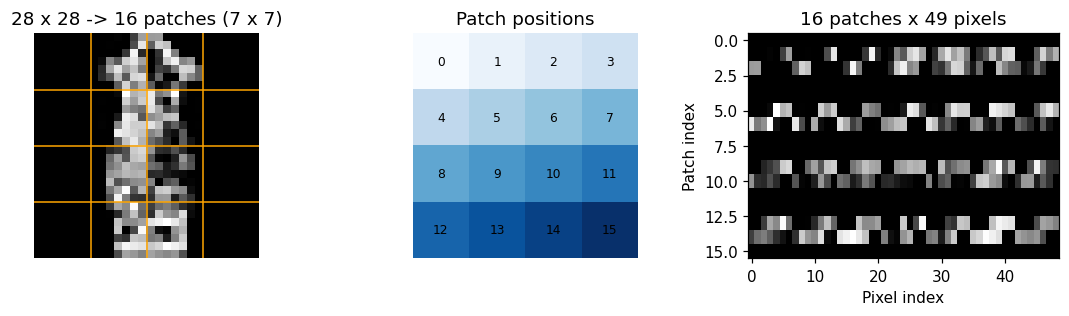

In [4]:
def patchify(images):
    images = np.asarray(images)
    assert images.ndim == 3 and images.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE)
    b = len(images)
    return images.reshape(b, GRID, PATCH, GRID, PATCH).transpose(0, 1, 3, 2, 4).reshape(b, N_PATCH, PATCH_DIM)

def unpatchify(patches):
    b = len(patches)
    return patches.reshape(b, GRID, GRID, PATCH, PATCH).transpose(0, 1, 3, 2, 4).reshape(b, IMAGE_SIZE, IMAGE_SIZE)

train_patches = patchify(X_train)
val_patches = patchify(X_val)
assert np.array_equal(unpatchify(train_patches[:2]), X_train[:2])
print('images:', X_train.shape, '-> patches:', train_patches.shape)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(X_train[0], cmap='gray', vmin=-1, vmax=1)
for boundary in range(PATCH, IMAGE_SIZE, PATCH):
    axes[0].axhline(boundary - .5, color='orange', lw=1)
    axes[0].axvline(boundary - .5, color='orange', lw=1)
axes[0].set_title(f'{IMAGE_SIZE} x {IMAGE_SIZE} -> {N_PATCH} patches ({PATCH} x {PATCH})'); axes[0].axis('off')
axes[1].imshow(np.arange(N_PATCH).reshape(GRID, GRID), cmap='Blues')
# 196・784個の番号を詰め込まず、細かいパッチでは色で配置を示す。
if GRID <= 7:
    for row in range(GRID):
        for col in range(GRID):
            axes[1].text(col, row, str(row * GRID + col), ha='center', va='center', fontsize=8)
axes[1].set_title('Patch positions'); axes[1].axis('off')
axes[2].imshow(train_patches[0], aspect='auto', cmap='gray', vmin=-1, vmax=1)
axes[2].set_title(f'{N_PATCH} patches x {PATCH_DIM} pixels')
axes[2].set_xlabel('Pixel index'); axes[2].set_ylabel('Patch index')
plt.tight_layout(); plt.show()


## 4. TF01の部品を再利用する

`attn_f`、`ffn_f`、`ln_f` はTF01と同じ基本実装です。画像分類では因果マスクを使いません。
Q・K・Vはそれぞれ64次元で、4ヘッドに分けるので1ヘッド16次元です。
Attention行列は画像ごと・ヘッドごとに`N_TOKEN × N_TOKEN`（初期設定17×17）となり、各行の合計は1です。

`SwiGLU(x) = (SiLU(x @ Wg) * (x @ Wu)) @ Wd`

Linearのバイアスは、元のTF01に合わせてAttentionとMLPでは省きます。
パッチ変換と最後の分類層にはバイアスを付け、LayerNormは倍率と補正値を学習します。
「全てのノードに必ずバイアスがある」という数え方にはなりません。


In [5]:
def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def attn_f(x, P, causal=False):
    """Multi-Head Self-Attention。x: (B, L, D) → (B, L, D)"""
    B, L, _ = x.shape
    dt = x.dtype.type
    split = lambda t: t.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)   # (B, ヘッド, L, HD)
    q = split(x @ P["Wq"])
    k = split(x @ P["Wk"])
    v = split(x @ P["Wv"])
    sc = q @ k.transpose(0, 1, 3, 2) * dt(1 / np.sqrt(HD))                 # (B, ヘッド, L, L)
    if causal:
        sc = np.where(np.triu(np.ones((L, L), dtype=bool), 1), dt(-1e9), sc)
    A = softmax(sc)
    o = (A @ v).transpose(0, 2, 1, 3).reshape(B, L, D)                     # ヘッドをつなげる
    return o @ P["Wo"], (x, q, k, v, A, o)

def ffn_f(x, P):
    """SwiGLU 型 MLP。x: (B, L, D) → (B, L, D)"""
    a = x @ P["Wg"]                 # Gate 用
    b = x @ P["Wu"]                 # Up
    sg = 1 / (1 + np.exp(-a))
    s_ = a * sg                     # SiLU(a) = a × sigmoid(a)
    h = s_ * b                      # ゲートを通す（要素ごとの積）
    return h @ P["Wd"], (x, a, b, sg, s_, h)

def ln_f(x, g, b):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    inv = 1 / np.sqrt(var + 1e-5)
    xh = (x - mu) * inv
    return xh * g + b, (xh, inv, g)

def make_dropout(shape, rate, rng, dtype):
    if rate == 0 or rng is None:
        return None
    return (rng.random(shape) >= rate).astype(dtype) / dtype(1 - rate)


## 5. 1ブロックのViTを組み立てる

```
画像パッチ → Linear → CLSを追加 → 位置Embeddingを足す
 → LayerNorm → Self-Attention → Residual
 → LayerNorm → SwiGLU MLP     → Residual
 → Final LayerNorm → CLSだけ取り出す → Linear(64→10) → Softmax
```

パッチのLinearは入力画素数に応じて初期化します。その他の行列はTF01と同じ小さな乱数です。
位置情報・CLS・重みはすべて逆伝播で学習します。


In [6]:
def init_params(seed=0, dtype=np.float32):
    r = np.random.default_rng(seed)
    n = lambda *shape: r.normal(0, .02, shape)
    p = {
        'Wpatch': r.normal(0, np.sqrt(1 / PATCH_DIM), (PATCH_DIM, D)),
        'bpatch': np.zeros(D), 'cls': n(1, 1, D), 'pos': n(1, N_TOKEN, D),
        'ln1_g': np.ones(D), 'ln1_b': np.zeros(D),
        'Wq': n(D, D), 'Wk': n(D, D), 'Wv': n(D, D), 'Wo': n(D, D),
        'ln2_g': np.ones(D), 'ln2_b': np.zeros(D),
        'Wg': n(D, D_FF), 'Wu': n(D, D_FF), 'Wd': n(D_FF, D),
        'lnf_g': np.ones(D), 'lnf_b': np.zeros(D),
        'Wout': n(D, N_CLASS), 'bout': np.zeros(N_CLASS),
    }
    return {k: v.astype(dtype) for k, v in p.items()}

def forward(P, patches, labels=None, rng=None, dropout=0.0):
    """パッチ(B,N_PATCH,PATCH_DIM) -> 画像分類。labels指定時は損失、未指定時はlogitsを返す。"""
    B = len(patches)
    dt = P['Wpatch'].dtype.type
    tokens = patches @ P['Wpatch'] + P['bpatch']
    h0 = np.concatenate([np.broadcast_to(P['cls'], (B, 1, D)), tokens], axis=1)
    if USE_POSITION:
        h0 = h0 + P['pos']
    masks = tuple(make_dropout(h0.shape, dropout, rng, dt) for _ in range(3))
    m0, m1, m2 = masks
    if m0 is not None:
        h0 = h0 * m0
    n1, c_ln1 = ln_f(h0, P['ln1_g'], P['ln1_b'])
    ao, c_att = attn_f(n1, P, causal=False)
    if m1 is not None:
        ao = ao * m1
    h1 = h0 + ao
    n2, c_ln2 = ln_f(h1, P['ln2_g'], P['ln2_b'])
    mo, c_ffn = ffn_f(n2, P)
    if m2 is not None:
        mo = mo * m2
    h2 = h1 + mo
    nf, c_lnf = ln_f(h2, P['lnf_g'], P['lnf_b'])
    cls_out = nf[:, 0, :]
    logits = cls_out @ P['Wout'] + P['bout']
    probs = softmax(logits)
    cache = dict(patches=patches, labels=labels, masks=masks,
                 c_ln1=c_ln1, c_att=c_att, c_ln2=c_ln2, c_ffn=c_ffn,
                 nf=nf, c_lnf=c_lnf, cls_out=cls_out, p=probs)
    if labels is None:
        return logits, cache
    # 安定したlog-sum-exp。逆伝播のp-one_hotと対応する損失。
    z = logits - logits.max(axis=-1, keepdims=True)
    loss = (np.log(np.exp(z).sum(axis=-1)) - z[np.arange(B), labels]).mean()
    return float(loss), cache

P = init_params(SEED)
groups = {
    'Patch embedding': ['Wpatch', 'bpatch'],
    'CLS + position': ['cls', 'pos'],
    'Attention Q/K/V/O': ['Wq', 'Wk', 'Wv', 'Wo'],
    'SwiGLU Up/Gate/Down': ['Wu', 'Wg', 'Wd'],
    'LayerNorm x 3': ['ln1_g', 'ln1_b', 'ln2_g', 'ln2_b', 'lnf_g', 'lnf_b'],
    'Classifier': ['Wout', 'bout'],
}
for label, names in groups.items():
    print(f'{label:24s}: {sum(P[k].size for k in names):,}')
PARAM_COUNT = sum(w.size for w in P.values())
print(f'TOTAL: {PARAM_COUNT:,} = {PARAM_COUNT / 1000:.3f}K parameters')
loss0, demo = forward(P, train_patches[:BATCH], y_train[:BATCH])
print(f'initial loss={loss0:.3f}, random uniform loss ln(10)={np.log(10):.3f}')
print('patch vectors:', demo['c_att'][0].shape, '/ attention:', demo['c_att'][4].shape)
assert np.allclose(demo['c_att'][4].sum(axis=-1), 1, atol=1e-6)


Patch embedding         : 3,200
CLS + position          : 1,152
Attention Q/K/V/O       : 16,384
SwiGLU Up/Gate/Down     : 49,152
LayerNorm x 3           : 384
Classifier              : 650
TOTAL: 70,922 = 70.922K parameters
initial loss=2.326, random uniform loss ln(10)=2.303
patch vectors: (32, 17, 64) / attention: (32, 4, 17, 17)


## 6. 手書きの逆伝播：画像の入り口まで学習する

TF01の `ln_b`、`lin_b`、`attn_b`、`ffn_b` をそのまま再利用します。
変更箇所は、10クラス分類からの勾配、CLSの勾配、位置Embeddingの勾配、パッチLinearの勾配です。
画像の画素自体は学習しません。**WpatchやAttentionを含む全モデルパラメータ** を更新します。


In [7]:
def ln_b(dy, c):
    xh, inv, g = c
    dg = (dy * xh).sum((0, 1)); db = dy.sum((0, 1)); dxh = dy * g
    dx = inv * (dxh - dxh.mean(-1, keepdims=True) - xh * (dxh * xh).mean(-1, keepdims=True))
    return dx, dg, db

def lin_b(dy, x, W):
    """y = x W の逆伝播。dx と dW を返す"""
    x2 = x.reshape(-1, x.shape[-1]); d2 = dy.reshape(-1, dy.shape[-1])
    return (d2 @ W.T).reshape(x.shape), x2.T @ d2

def attn_b(dout, P, c):
    x, q, k, v, A, o = c
    B, L, _ = x.shape
    dt = x.dtype.type
    g = {}
    do, g["Wo"] = lin_b(dout, o, P["Wo"])
    do = do.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)
    dA = do @ v.transpose(0, 1, 3, 2)
    dv = A.transpose(0, 1, 3, 2) @ do
    dsc = A * (dA - (dA * A).sum(-1, keepdims=True)) * dt(1 / np.sqrt(HD))   # softmax の逆伝播
    dq = dsc @ k
    dk = dsc.transpose(0, 1, 3, 2) @ q
    merge = lambda t: t.transpose(0, 2, 1, 3).reshape(B, L, D)
    dxq, g["Wq"] = lin_b(merge(dq), x, P["Wq"])
    dxk, g["Wk"] = lin_b(merge(dk), x, P["Wk"])
    dxv, g["Wv"] = lin_b(merge(dv), x, P["Wv"])
    return dxq + dxk + dxv, g

def ffn_b(dout, P, c):
    x, a, b, sg, s_, h = c
    g = {}
    dh, g["Wd"] = lin_b(dout, h, P["Wd"])
    ds, db = dh * b, dh * s_
    da = ds * (sg * (1 + a * (1 - sg)))                                       # SiLU の微分
    dxa, g["Wg"] = lin_b(da, x, P["Wg"])
    dxb, g["Wu"] = lin_b(db, x, P["Wu"])
    return dxa + dxb, g


In [8]:
def backward(P, cache):
    patches, labels = cache['patches'], cache['labels']
    B = len(labels)
    m0, m1, m2 = cache['masks']
    G = {}
    dl = cache['p'].copy()
    dl[np.arange(B), labels] -= 1
    dl /= B
    dcls, G['Wout'] = lin_b(dl, cache['cls_out'], P['Wout'])
    G['bout'] = dl.sum(axis=0)
    dnf = np.zeros_like(cache['nf'])
    dnf[:, 0, :] = dcls
    dh2, G['lnf_g'], G['lnf_b'] = ln_b(dnf, cache['c_lnf'])

    dmo = dh2 * m2 if m2 is not None else dh2
    dn2, gf = ffn_b(dmo, P, cache['c_ffn']); G.update(gf)
    dh1_ln, G['ln2_g'], G['ln2_b'] = ln_b(dn2, cache['c_ln2'])
    dh1 = dh2 + dh1_ln
    dao = dh1 * m1 if m1 is not None else dh1
    dn1, ga = attn_b(dao, P, cache['c_att']); G.update(ga)
    dh0_ln, G['ln1_g'], G['ln1_b'] = ln_b(dn1, cache['c_ln1'])
    dh0 = dh1 + dh0_ln
    if m0 is not None:
        dh0 = dh0 * m0
    G['pos'] = dh0.sum(axis=0, keepdims=True) if USE_POSITION else np.zeros_like(P['pos'])
    G['cls'] = dh0[:, :1, :].sum(axis=0, keepdims=True)
    _, G['Wpatch'] = lin_b(dh0[:, 1:, :], patches, P['Wpatch'])
    G['bpatch'] = dh0[:, 1:, :].sum(axis=(0, 1))
    assert set(G) == set(P)
    return G


## 7. 勾配チェック：数値微分と一致するか

float64・ドロップアウトなしで、**各パラメータ配列の2要素**を中心差分と比較します。
全要素を検査するものではありませんが、パッチEmbeddingやCLSまで勾配がつながることを確認できます。
一致しない場合はassertで停止し、誤った逆伝播のまま学習を続けません。


In [9]:
Pc = init_params(seed=1, dtype=np.float64)
xc = train_patches[:2].astype(np.float64)
yc = y_train[:2]
_, cc = forward(Pc, xc, yc)
Gc = backward(Pc, cc)
rcheck = np.random.default_rng(5)
worst_rel, worst_abs = 0.0, 0.0
checked = 0
for name in Pc:
    for _ in range(2):
        idx = tuple(int(rcheck.integers(s)) for s in Pc[name].shape)
        old = Pc[name][idx]
        eps = 1e-5
        Pc[name][idx] = old + eps; lp, _ = forward(Pc, xc, yc)
        Pc[name][idx] = old - eps; lm, _ = forward(Pc, xc, yc)
        Pc[name][idx] = old
        numeric, analytic = (lp - lm) / (2 * eps), float(Gc[name][idx])
        absolute = abs(numeric - analytic)
        relative = absolute / max(1e-6, abs(numeric) + abs(analytic))
        worst_abs, worst_rel = max(worst_abs, absolute), max(worst_rel, relative)
        checked += 1
        assert np.isclose(numeric, analytic, rtol=2e-3, atol=2e-7), (name, idx, numeric, analytic)
print(f'Gradient check PASS: {checked} values, max abs={worst_abs:.2e}, max rel={worst_rel:.2e}')


Gradient check PASS: 38 values, max abs=2.27e-10, max rel=1.96e-07


## 8. 学習前の分類を記録する

検証データをバッチに分けて評価し、大きな中間配列を一度に作らないようにします。
初期化モデルの正解率を保存し、同じ検証画像で学習後と比較します。
ランダムな10択の期待正解率は10%ですが、初期化モデルが必ず10%になるわけではありません。


In [10]:
def predict_all(P, patches, batch_size=None):
    # 小さいパッチで巨大なAttention配列を作らないよう、明示値も安全側に抑える。
    batch_size = EVAL_BATCH if batch_size is None else min(batch_size, SAFE_BATCH)
    if batch_size < 1:
        raise ValueError('batch_sizeは1以上にしてください')
    probs = []
    for start in range(0, len(patches), batch_size):
        _, cache = forward(P, patches[start:start + batch_size])
        probs.append(cache['p'])
    return np.concatenate(probs, axis=0)

def evaluate(P, patches, labels):
    probs = predict_all(P, patches)
    pred = probs.argmax(axis=-1)
    loss = -np.log(np.maximum(probs[np.arange(len(labels)), labels], 1e-12)).mean()
    return float(loss), float(np.mean(pred == labels))

P_initial = init_params(SEED)
before_probs = predict_all(P_initial, val_patches)
before_pred = before_probs.argmax(axis=-1)
before_loss, before_acc = evaluate(P_initial, val_patches, y_val)
print(f'Before training: validation loss={before_loss:.4f}, accuracy={before_acc:.2%}')


Before training: validation loss=2.3211, accuracy=11.00%


## 9. AdamWで学習する：全学習画像をエポックごとに使う

各エポックの先頭で54,000枚をシャッフルし、`BATCH` 枚ずつ重複なしで取り出します。
最後の小さいバッチも使います。初期設定PATCH=7では32枚ずつ、1エポック1,688ステップ、8エポック13,504ステップです。
パッチ1・2ではメモリ対策でBATCHが小さくなるので、1エポックのステップ数も自動計算し直します。
各エポック末に検証し、検証損失が最小のモデルを選びます。公式テストは最後だけで評価します。

順伝播 → 損失 → 逆伝播 → 勾配クリッピング → AdamWの順で更新します。
重み減衰の対象はTF01と同じくLinearの重みだけです。
学習時間（TRAIN_SECONDS）は検証時間を含むループの実測時間です。
300秒で終了した場合は完了エポックと実際に使った画像数を表示します。


In [11]:
P = init_params(SEED)
m = {k: np.zeros_like(w) for k, w in P.items()}
v2 = {k: np.zeros_like(w) for k, w in P.items()}
rng = np.random.default_rng(SEED)
DECAY_KEYS = {'Wpatch', 'Wq', 'Wk', 'Wv', 'Wo', 'Wg', 'Wu', 'Wd', 'Wout'}
hist = {'step': [0], 'train_loss': [None], 'val_loss': [before_loss],
        'val_accuracy': [before_acc], 'seconds': [0.0]}
best_loss = before_loss
best_step = 0
best_P = {k: w.copy() for k, w in P.items()}
run_loss = []
samples_seen = 0
coverage = np.zeros(len(y_train), dtype=np.int32)
validation_seconds = 0.0
t0 = time.perf_counter()
stop_reason = 'STEPS'

for step in range(1, STEPS + 1):
    lr = LR * min(1.0, step / 50) * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * step / STEPS)))
    batch_index = (step - 1) % STEPS_PER_EPOCH
    if batch_index == 0:
        epoch_order = rng.permutation(len(y_train))
    indices = epoch_order[batch_index * BATCH:(batch_index + 1) * BATCH]
    samples_seen += len(indices)
    coverage[indices] += 1
    loss, cache = forward(P, train_patches[indices], y_train[indices], rng=rng, dropout=DROPOUT)
    G = backward(P, cache)
    assert np.isfinite(loss) and all(np.isfinite(g).all() for g in G.values()), '損失または勾配が非有限です'
    run_loss.append(loss)
    grad_norm = float(np.sqrt(sum(np.sum(g.astype(np.float64)**2) for g in G.values())))
    scale = min(1.0, 1.0 / (grad_norm + 1e-6))
    for k in P:
        g = G[k] * scale
        m[k] = .9 * m[k] + .1 * g
        v2[k] = .999 * v2[k] + .001 * g * g
        mh = m[k] / (1 - .9**step)
        vh = v2[k] / (1 - .999**step)
        if k in DECAY_KEYS:
            P[k] -= lr * WEIGHT_DECAY * P[k]
        P[k] -= lr * mh / (np.sqrt(vh) + 1e-8)
    elapsed = time.perf_counter() - t0
    time_up = MAX_TRAIN_SECONDS is not None and elapsed >= MAX_TRAIN_SECONDS
    if step == 1 or step % EVAL_EVERY == 0 or step == STEPS or time_up:
        validation_t0 = time.perf_counter()
        vl, va = evaluate(P, val_patches, y_val)
        validation_seconds += time.perf_counter() - validation_t0
        elapsed = time.perf_counter() - t0
        hist['step'].append(step); hist['train_loss'].append(float(np.mean(run_loss)))
        hist['val_loss'].append(vl); hist['val_accuracy'].append(va); hist['seconds'].append(elapsed)
        if vl < best_loss:
            best_loss, best_step = vl, step
            best_P = {k: w.copy() for k, w in P.items()}
        print(f'step {step:4d}/{STEPS}  train loss={np.mean(run_loss):.3f}  '
              f'val loss={vl:.3f}  val acc={va:.1%}  {elapsed:.1f}s', flush=True)
        run_loss = []
        time_up = MAX_TRAIN_SECONDS is not None and elapsed >= MAX_TRAIN_SECONDS
    if time_up:
        stop_reason = 'MAX_TRAIN_SECONDS'
        break

TRAIN_SECONDS = time.perf_counter() - t0
COMPLETED_STEPS = step
P_last = {k: w.copy() for k, w in P.items()}  # 最終更新時点の重みも残す
P = {k: w.copy() for k, w in best_P.items()}
after_loss, after_acc = evaluate(P, val_patches, y_val)
print(f'Finished: {COMPLETED_STEPS} steps, {TRAIN_SECONDS:.1f}s, reason={stop_reason}')
print(f'Samples seen: {samples_seen:,} ({samples_seen / len(y_train):.2f} epochs), unique images: {np.count_nonzero(coverage):,}/{len(y_train):,}')
print(f'Coverage per image: min={coverage.min()}, max={coverage.max()}, validation included={validation_seconds:.1f}s')
if stop_reason == 'STEPS':
    assert samples_seen == EPOCHS * len(y_train)
    assert np.all(coverage == EPOCHS), '全学習画像を各エポック1回使えていません'
print(f'Selected by validation loss: step={best_step}, val accuracy {before_acc:.1%} -> {after_acc:.1%}')


step    1/13504  train loss=2.301  val loss=2.320  val acc=11.1%  0.7s
step 1688/13504  train loss=0.742  val loss=0.537  val acc=81.3%  11.9s
step 3376/13504  train loss=0.519  val loss=0.516  val acc=81.7%  21.8s
step 5064/13504  train loss=0.466  val loss=0.456  val acc=83.5%  31.9s
step 6752/13504  train loss=0.428  val loss=0.446  val acc=84.3%  41.8s
step 8440/13504  train loss=0.402  val loss=0.418  val acc=85.0%  51.8s
step 10128/13504  train loss=0.376  val loss=0.404  val acc=85.9%  61.8s
step 11816/13504  train loss=0.356  val loss=0.393  val acc=86.1%  71.8s
step 13504/13504  train loss=0.343  val loss=0.384  val acc=86.5%  81.7s
Finished: 13504 steps, 81.7s, reason=STEPS
Samples seen: 432,000 (8.00 epochs), unique images: 54,000/54,000
Coverage per image: min=8, max=8, validation included=5.5s
Selected by validation loss: step=13504, val accuracy 11.0% -> 86.5%


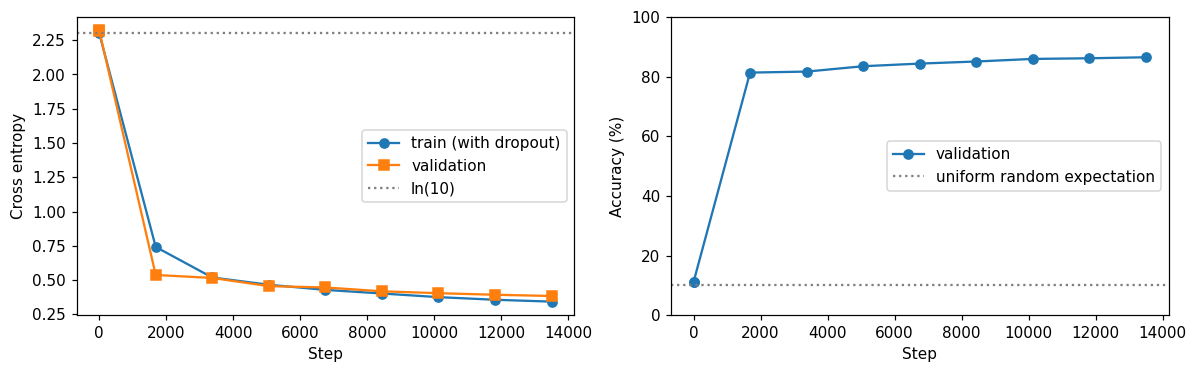

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(hist['step'][1:], hist['train_loss'][1:], 'o-', label='train (with dropout)')
axes[0].plot(hist['step'], hist['val_loss'], 's-', label='validation')
axes[0].axhline(np.log(N_CLASS), color='gray', ls=':', label='ln(10)')
axes[0].set_xlabel('Step'); axes[0].set_ylabel('Cross entropy'); axes[0].legend()
axes[1].plot(hist['step'], np.array(hist['val_accuracy']) * 100, 'o-', label='validation')
axes[1].axhline(10, color='gray', ls=':', label='uniform random expectation')
axes[1].set_xlabel('Step'); axes[1].set_ylabel('Accuracy (%)'); axes[1].set_ylim(0, 100)
axes[1].legend()
plt.tight_layout(); plt.show()


## 10. 同じ画像で学習前後を比較する

クラスごとに検証画像を1枚ずつ選び、**同じ画像を学習前・学習後で並べます**。
Tは正解、Pは予測です。緑は正解、赤は誤りです。確率はモデルの出力値であり、正しさの保証ではありません。


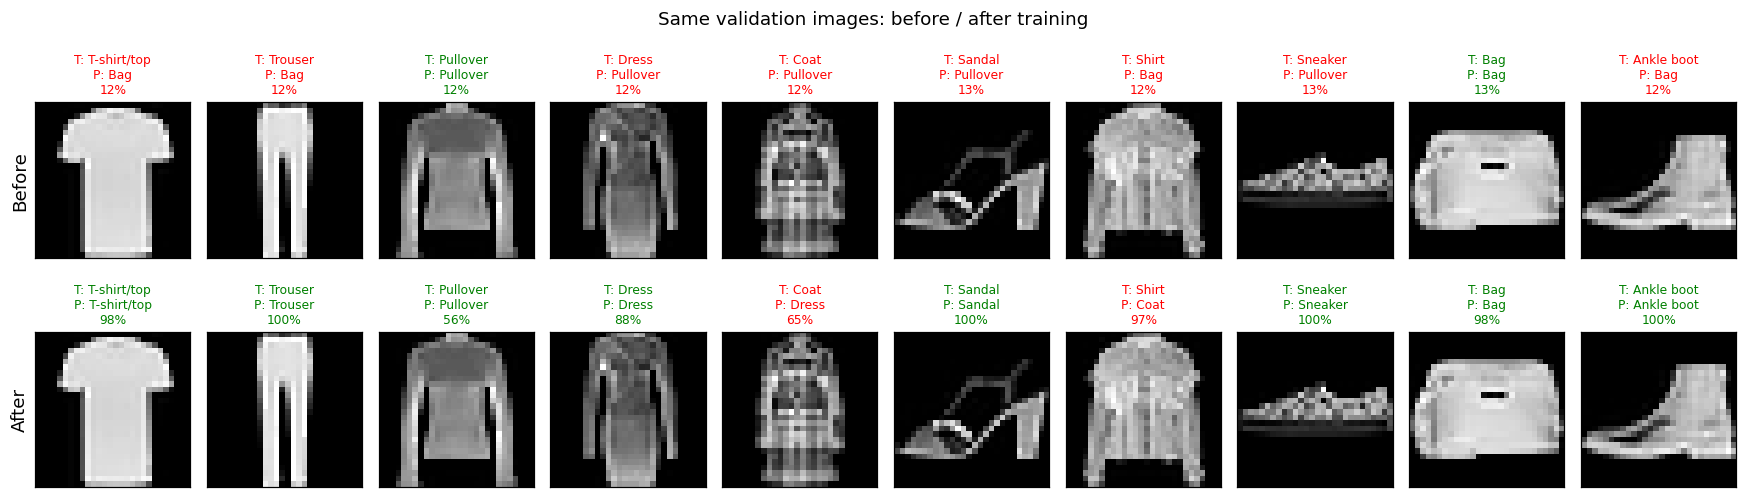

In [13]:
after_probs = predict_all(P, val_patches)
after_pred = after_probs.argmax(axis=-1)
example_ids = np.array([np.flatnonzero(y_val == c)[0] for c in range(N_CLASS)])
fig, axes = plt.subplots(2, N_CLASS, figsize=(16, 5))
for row, (title, probs, preds) in enumerate([
    ('Before', before_probs, before_pred), ('After', after_probs, after_pred)]):
    for col, idx in enumerate(example_ids):
        ax = axes[row, col]
        pred = int(preds[idx]); true = int(y_val[idx])
        ax.imshow(X_val[idx], cmap='gray', vmin=-1, vmax=1)
        ax.set_title(f'T: {CLASS_NAMES[true]}\nP: {CLASS_NAMES[pred]}\n{probs[idx, pred]:.0%}',
                     fontsize=8, color='green' if pred == true else 'red')
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(title, fontsize=12)
fig.suptitle('Same validation images: before / after training')
plt.tight_layout(); plt.show()


## 11. 公式テスト10,000枚で最終評価する

ここで初めて公式テストを分類します。選択した最良モデルの精度と、クラスごとの適合率・再現率・F1を計算します。
混同行列は **行＝正解、列＝予測** です。テスト結果を見て設定を繰り返し選ぶと、
そのテストへの適合が起きるので、設定比較は検証データで行います。


Official test accuracy: 86.26% (8626/10000)
class           precision     recall         F1
T-shirt/top         0.830      0.797      0.813
Trouser             0.982      0.965      0.973
Pullover            0.771      0.793      0.782
Dress               0.865      0.866      0.866
Coat                0.775      0.784      0.780
Sandal              0.933      0.946      0.939
Shirt               0.656      0.655      0.656
Sneaker             0.920      0.923      0.922
Bag                 0.952      0.956      0.954
Ankle boot          0.944      0.941      0.942
macro               0.863      0.863      0.863


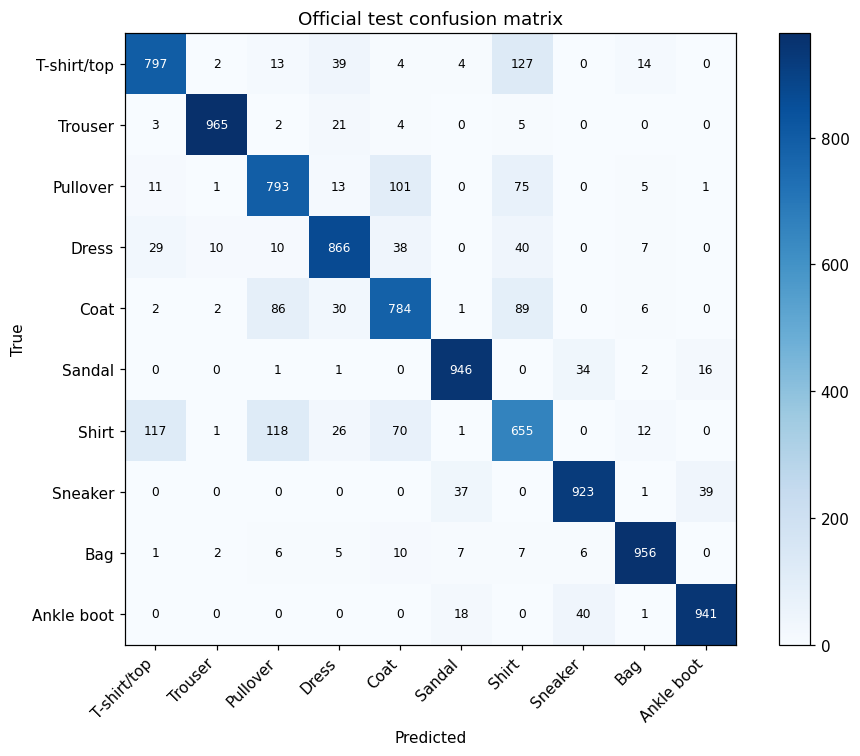

In [14]:
test_patches = patchify(normalize(raw_test))
test_probs = predict_all(P, test_patches)
test_pred = test_probs.argmax(axis=-1)
confusion = np.zeros((N_CLASS, N_CLASS), dtype=np.int64)
np.add.at(confusion, (raw_test_y, test_pred), 1)
assert confusion.sum() == 10000
TEST_ACCURACY = float(np.trace(confusion) / confusion.sum())
tp = np.diag(confusion).astype(np.float64)
precision = tp / np.maximum(confusion.sum(axis=0), 1)
recall = tp / np.maximum(confusion.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
print(f'Official test accuracy: {TEST_ACCURACY:.2%} ({np.trace(confusion)}/{confusion.sum()})')
print(f'{"class":14s} {"precision":>10s} {"recall":>10s} {"F1":>10s}')
for i in range(N_CLASS):
    print(f'{CLASS_NAMES[i]:14s} {precision[i]:10.3f} {recall[i]:10.3f} {f1[i]:10.3f}')
print(f'{"macro":14s} {precision.mean():10.3f} {recall.mean():10.3f} {f1.mean():10.3f}')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion, cmap='Blues')
for i in range(N_CLASS):
    for j in range(N_CLASS):
        ax.text(j, i, str(confusion[i, j]), ha='center', va='center', fontsize=8,
                color='white' if confusion[i, j] > confusion.max() / 2 else 'black')
ax.set_xticks(range(N_CLASS)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(N_CLASS)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Official test confusion matrix')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


### 間違えた画像を見る

誤りだけを見て「どのような見た目を混同したか」を確認します。
Tシャツ・シャツ・プルオーバー・コートなどは小さい白黒画像では似て見える場合があります。


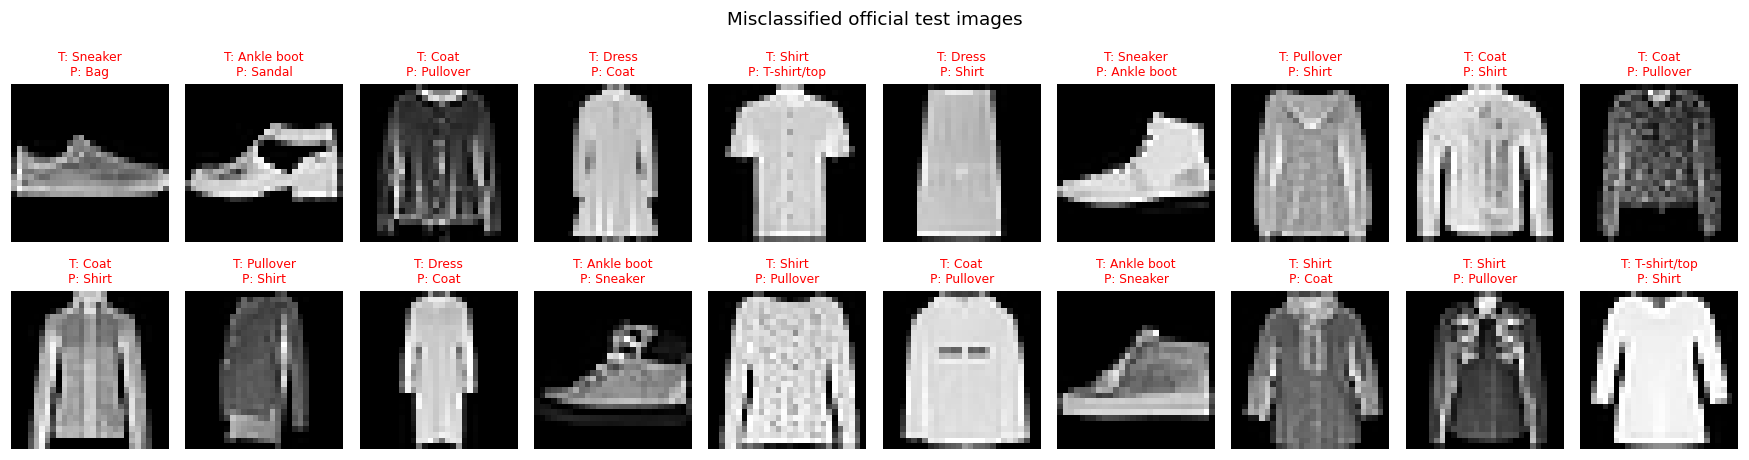

In [15]:
wrong_ids = np.flatnonzero(test_pred != raw_test_y)[:20]
if len(wrong_ids):
    fig, axes = plt.subplots(2, 10, figsize=(16, 4.5))
    for ax, idx in zip(axes.flat, wrong_ids):
        true, pred = int(raw_test_y[idx]), int(test_pred[idx])
        ax.imshow(raw_test[idx], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'T: {CLASS_NAMES[true]}\nP: {CLASS_NAMES[pred]}', fontsize=8, color='red')
    for ax in axes.flat:
        ax.axis('off')
    fig.suptitle('Misclassified official test images')
    plt.tight_layout(); plt.show()
else:
    print('この実行ではテスト画像の誤分類がありませんでした。')


## 12. Attentionを見る：CLSがどのパッチを参照したか

学習前後の各ヘッドについて、CLSから各パッチへのAttentionを `GRID × GRID` に並べます（初期設定4×4）。
CLS自身への重みは画像外なので省いています。パッチの重み合計は1以下です。
**学習前後・全ヘッドを同じ色スケール**で描き、値の比較ができるようにします。

Attentionは内部の情報の混ぜ方です。**明るい場所がそのまま「判断理由」になるとは限りません。**
1ブロックしかないため、複雑で鮮明な物体の輪郭が必ず現れるわけでもありません。


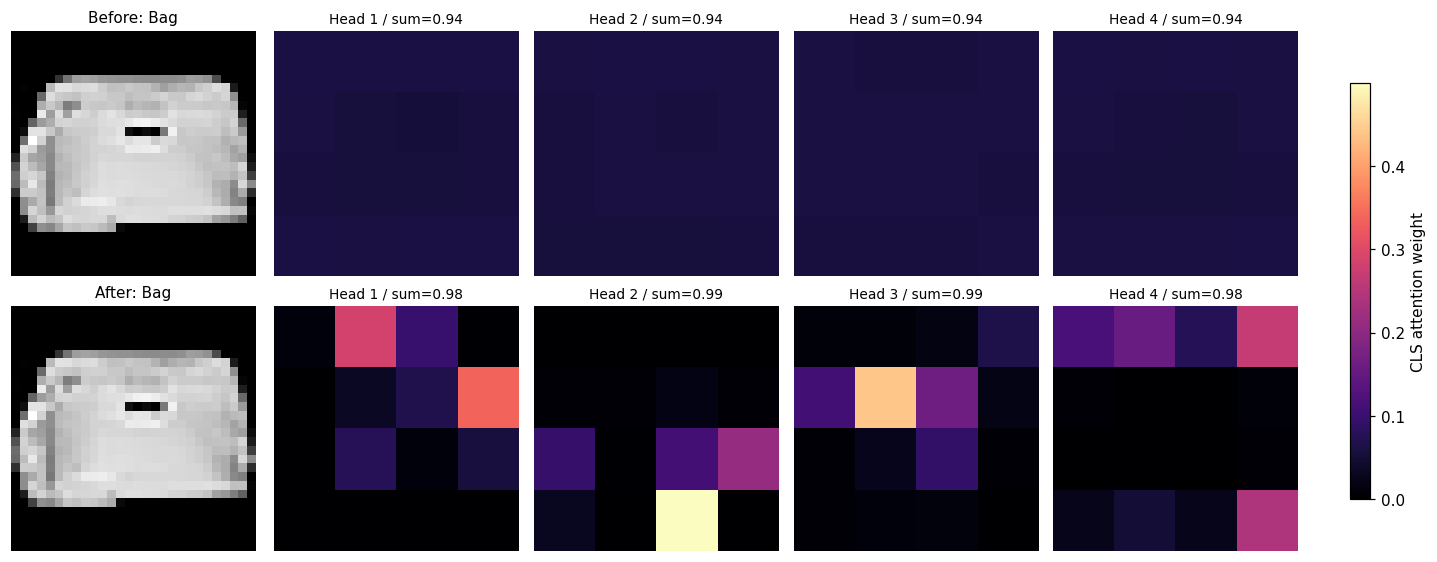

In [16]:
ATTENTION_SAMPLE = int(example_ids[8])  # 検証データのバッグ。別の画像番号に変更できます。
assert 0 <= ATTENTION_SAMPLE < len(y_val)
_, cache_before = forward(P_initial, val_patches[ATTENTION_SAMPLE:ATTENTION_SAMPLE + 1])
_, cache_after = forward(P, val_patches[ATTENTION_SAMPLE:ATTENTION_SAMPLE + 1])
maps_before = cache_before['c_att'][4][0, :, 0, 1:].reshape(N_HEAD, GRID, GRID)
maps_after = cache_after['c_att'][4][0, :, 0, 1:].reshape(N_HEAD, GRID, GRID)
vmax = max(float(maps_before.max()), float(maps_after.max()), 1e-6)
fig, axes = plt.subplots(2, N_HEAD + 1, figsize=(13, 5), constrained_layout=True)
for row, (label, maps) in enumerate([('Before', maps_before), ('After', maps_after)]):
    axes[row, 0].imshow(X_val[ATTENTION_SAMPLE], cmap='gray', vmin=-1, vmax=1)
    axes[row, 0].set_title(f'{label}: {CLASS_NAMES[y_val[ATTENTION_SAMPLE]]}', fontsize=10)
    axes[row, 0].axis('off')
    for h in range(N_HEAD):
        im = axes[row, h + 1].imshow(maps[h], cmap='magma', vmin=0, vmax=vmax)
        axes[row, h + 1].set_title(f'Head {h + 1} / sum={maps[h].sum():.2f}', fontsize=9)
        axes[row, h + 1].axis('off')
fig.colorbar(im, ax=axes[:, 1:].ravel().tolist(), label='CLS attention weight', shrink=.8)
plt.show()


## 13. 学習結果を保存する

`tf02_results/patch_7/` など、パッチサイズ別のフォルダにモデルと実測メトリクスを保存します。
同じパッチサイズで再実行した場合は、そのフォルダ内の同名の結果を更新します。
モデルにはハイパーパラメータ・クラス名・正規化方法・選択されたステップも保存するので、
後で何を学習した重みか確認できます。データは `fashion_mnist/` に残ります。

`tf02_fashion_model.npz` は検証損失最小のモデル、`tf02_fashion_model_last.npz` は最終更新時点のモデルです。
時間制限で途中終了した場合、lastは8エポック目とは限りません。保存されたcompleted_epochsも確認してください。


In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
config = dict(D=D, N_HEAD=N_HEAD, HD=HD, D_FF=D_FF, PATCH=PATCH, IMAGE_SIZE=IMAGE_SIZE,
              N_CLASS=N_CLASS, N_TOKEN=N_TOKEN, GRID=GRID, N_PATCH=N_PATCH, PATCH_DIM=PATCH_DIM, USE_POSITION=USE_POSITION,
              TRAIN_PER_CLASS=TRAIN_PER_CLASS, VAL_PER_CLASS=VAL_PER_CLASS,
              EPOCHS=EPOCHS, STEPS_PER_EPOCH=STEPS_PER_EPOCH, sampling="shuffle_without_replacement_per_epoch",
              BATCH=BATCH, EVAL_BATCH=EVAL_BATCH, REQUESTED_BATCH=REQUESTED_BATCH,
              REQUESTED_EVAL_BATCH=REQUESTED_EVAL_BATCH, MAX_ATTENTION_ELEMENTS=MAX_ATTENTION_ELEMENTS, STEPS=STEPS, MAX_TRAIN_SECONDS=MAX_TRAIN_SECONDS,
              EVAL_EVERY=EVAL_EVERY, LR=LR, WEIGHT_DECAY=WEIGHT_DECAY,
              DROPOUT=DROPOUT, SEED=SEED, normalization='uint8 / 127.5 - 1.0',
              pooling='CLS', blocks=1, mlp='SwiGLU', class_names=CLASS_NAMES,
              source_notebook='TF01_tiny_gpt_waka.ipynb')
metrics = dict(parameter_count=PARAM_COUNT, completed_steps=COMPLETED_STEPS,
               best_step=best_step, train_seconds=TRAIN_SECONDS, stop_reason=stop_reason,
               validation_seconds=validation_seconds, samples_seen=samples_seen,
               completed_epochs=samples_seen / len(y_train),
               unique_training_images=int(np.count_nonzero(coverage)),
               coverage_min=int(coverage.min()), coverage_max=int(coverage.max()),
               train_images=len(y_train), validation_images=len(y_val), test_images=len(raw_test_y),
               initial_val_accuracy=before_acc, final_val_accuracy=after_acc,
               test_accuracy=TEST_ACCURACY, macro_precision=float(precision.mean()),
               macro_recall=float(recall.mean()), macro_f1=float(f1.mean()),
               confusion=confusion.tolist())
np.savez_compressed(OUTPUT_DIR / 'tf02_fashion_model.npz', **P,
                    config_json=np.array(json.dumps(config, ensure_ascii=False)))
last_config = dict(config, model_selection='last_update', completed_steps=COMPLETED_STEPS,
                   completed_epochs=samples_seen / len(y_train))
np.savez_compressed(OUTPUT_DIR / 'tf02_fashion_model_last.npz', **P_last,
                    config_json=np.array(json.dumps(last_config, ensure_ascii=False)))
np.savez_compressed(OUTPUT_DIR / 'tf02_split_ids.npz', train_ids=train_ids, val_ids=val_ids)
(OUTPUT_DIR / 'tf02_metrics.json').write_text(
    json.dumps(dict(config=config, metrics=metrics, history=hist), ensure_ascii=False, indent=2), encoding='utf-8')
print('Saved:', (OUTPUT_DIR / 'tf02_fashion_model.npz').as_posix())
print('Saved:', (OUTPUT_DIR / 'tf02_metrics.json').as_posix())

print('Saved last update:', (OUTPUT_DIR / 'tf02_fashion_model_last.npz').as_posix())


Saved: tf02_results/patch_7/tf02_fashion_model.npz
Saved: tf02_results/patch_7/tf02_metrics.json
Saved last update: tf02_results/patch_7/tf02_fashion_model_last.npz


## やってみよう

| 変更する設定 | 比較すること |
|---|---|
| `EPOCHS = 1` / `4` / `8` | 学習回数・検証精度・時間の変化 |
| `USE_POSITION = False` | 位置情報を与えないとどう変わるか。同じ条件で学習し直す |
| `PATCH = 1` / `2` / `4` / `7` / `14` / `28` | それぞれ784 / 196 / 49 / 16 / 4 / 1パッチ。時間と検証精度を比較する |
| `DROPOUT = 0.0` / `0.1` | 訓練損失と検証損失の差 |
| `MAX_TRAIN_SECONDS = None` | 時間制限を外し、`STEPS`まで学習 |
| `N_HEAD = 1` / `4` / `8` | ヘッドごとのAttentionと精度。Dを固定すればQ/K/V/Oの重み数は変わらない |
| `D = 128`, `D_FF = 512` | 実際のパラメータ数、速度、精度の変化 |

検証IDを先に固定しています。初期設定では学習54,000枚＋検証6,000枚で公式訓練データをすべて使います。
公式テスト10,000枚を追加学習やモデル選択に使わないでください。

### パッチを1や2にすると精度が上がる？

細かい局所的な違いを扱いやすくなる可能性はありますが、**この教材で精度が上がるとは限りません**。
どのサイズも画素を捨てずにパッチ化するため、細分化だけで元画像の情報が増えるわけではありません。
小さいパッチは1トークンの局所情報が少なくなり、トークン間の関係を学習する負担が増えます。
大規模学習で見られる精度と速度のトレードオフが、この1ブロック・短時間学習でも同じ結果になるとは限りません。

| PATCH | パッチ数 | CLS込みトークン | Attention行列の要素数／ヘッド | PATCH=7に対する要素数比 |
|---:|---:|---:|---:|---:|
| 1 | 784 | 785 | 616,225 | 約2,132倍 |
| 2 | 196 | 197 | 38,809 | 約134倍 |
| 4 | 49 | 50 | 2,500 | 約8.65倍 |
| 7 | 16 | 17 | 289 | 1倍 |
| 14 | 4 | 5 | 25 | 約0.087倍 |
| 28 | 1 | 2 | 4 | 約0.014倍 |

PATCH=28は画像全体を1パッチにします。CLS込みで2トークンとなり、複数の画像領域間のAttentionを学ぶ構成ではありません。

これはAttention行列のサイズ比であり、学習全体の実測時間の倍率ではありません。
このノートは自動バッチ調整も行うため、同じ300秒で比べると学習できた画像数・更新回数も異なります。
実行時間の短い7・14・28から試し、必要なら4・2・1も比較してください。各実行で、検証精度だけでなく、
学習秒数・実際のバッチ数・完了エポック・使用画像数・最良ステップ・パラメータ数も確認します。
同じ画像分割・複数の乱数シードで比較し、モデルの選択には検証データを使います。
同じエポック数を最後まで比べる場合は `MAX_TRAIN_SECONDS = None` にしますが、細かいパッチほど時間がかかります。
この表は計算したサイズの比較であり、パッチ1・2の精度向上を実測した結果ではありません。

参考：[FlexiViT One Model for All Patch Sizes](https://arxiv.org/abs/2212.08013)。

### 前回のMLPより高精度になる？

この小規模・短時間設定では、ViTがMLPやCNNより高精度になる保証はありません。
目的は、**パッチ化・位置情報・Attention・CLSによる画像分類の仕組みを実装して観察すること**です。
このモデルは10分類用であり、画像について自然言語で会話するVLMではありません。

## 出典・実装の由来

- ベース実装：同じフォルダの `TF01_tiny_gpt_waka.ipynb`。Attention・SwiGLU・LayerNormと各逆伝播関数を再利用。
- データ：[Zalando Research / Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)。MIT License。
  Xiao, Rasul, Vollgraf, *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms* (2017)。
  配布元・チェックサム：[公式README](https://github.com/zalandoresearch/fashion-mnist#Get-the-Data)。
- ViT：Dosovitskiy et al., [*An Image is Worth 16x16 Words*](https://arxiv.org/abs/2010.11929) (2020/2021)。
- Transformer：Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) (2017)。
- AdamW：Loshchilov & Hutter, [*Decoupled Weight Decay Regularization*](https://arxiv.org/abs/1711.05101)。

このノートブックはFashion-MNISTを実行時に取得します。ダウンロードしたファイルを再配布する場合は、
[配布元のLICENSE](https://github.com/zalandoresearch/fashion-mnist/blob/master/LICENSE)も同梱してください。


## 全パッチを8エポック目で揃えた比較

2026年11月10日に作成者の同じPCで順に測定した記録です。**全て最終8エポック目の重み**で比較し、
途中で選ばれたモデルの値とは区別しています。現在の設定を実行するたびにこの表を更新するものではありません。

| PATCH | パッチ数 | CLS込みトークン | パラメータ数 | 学習バッチ数 | 検証精度 | テスト精度 | 学習ループ時間 |
|---|---:|---:|---:|---:|---:|---:|---|
| 1 | 784 | 785 | 117,002 | 1 | 84.85% | 84.34% | 6時間31分55秒 |
| 2 | 196 | 197 | 79,562 | 16 | 85.57% | 85.87% | 33分12秒 |
| 4 | 49 | 50 | 70,922 | 32 | 85.73% | 85.51% | 5分31秒 |
| 7 | 16 | 17 | 70,922 | 32 | 86.45% | 86.26% | 1分58秒 |
| 14 | 4 | 5 | 79,562 | 32 | 87.72% | 87.18% | 43秒 |
| 28 | 1 | 2 | 117,002 | 32 | 86.08% | 86.13% | 36秒 |

全条件で同一の学習54,000枚・検証6,000枚と公式テスト10,000枚を使い、SEED=0で各学習画像を8回使用しました。
PATCH=14のテスト精度が今回の条件では最も高くなりましたが、バッチ数・更新回数・パラメータ数も異なります。
各条件1シードの実測であり、一般的なパッチサイズの優劣を示すものではありません。

時間は学習ループ内の検証を含み、最終テストや図の描画などは含みません。PATCH=1はチェックポイント保存も含み、
PATCH=2は最終重みを取得するための再実行値です。同じPCでも負荷が変わるため、時間にはばらつきがあります。
PATCH=1・2を8エポックまで実行すると、初期設定の300秒を大きく超える場合があります。

PATCH=28は画像全体が1パッチとなり、CLS込み2トークンです。複数の画像領域間のAttentionを学ぶ構成ではありません。

通常のテスト評価と図は検証損失最小のモデル `P` を使います。最終更新時点のモデルは `P_last` です。
最終8エポック目の結果を比べる場合は、8エポック完了を確認してから、追加セルで次を実行できます。

```python
last_probs = predict_all(P_last, test_patches)
last_accuracy = np.mean(last_probs.argmax(-1) == raw_test_y)
print(f'Last update test accuracy: {last_accuracy:.2%}')
```

`tf02_fashion_model.npz` は検証損失最小、`tf02_fashion_model_last.npz` は最終更新時点の重みです。
時間制限で途中終了した場合、lastは8エポック目とは限らないため、保存設定の `completed_epochs` を確認してください。
テスト結果を基準に繰り返しモデルを選ぶことは避け、設定選択には検証データを使用してください。

このGitHub教材に学習済みの重みや過去の比較用JSONは含めていません。通常実行すると、選択したPATCHの
モデル・メトリクス・分割IDを `tf02_results/patch_<PATCH>/` に保存します。
